In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv("customers.csv")

#Removing duplicates
df = df.drop_duplicates()

#Cleaning gender column
df['gender'] = df['gender'].replace(
    {
        'M': 'Male',
        'F': 'Female',
        'Unknown': 'Not Specified',
        '': 'Not Specified'
    })
df['gender'] = df['gender'].fillna('Not Specified')

#Cleaning age column
df.loc[df['age'] < 0, 'age'] = np.nan
df['age'] = pd.to_numeric(
    df['age'],
    errors='coerce'
)

#Cleaning email column
df['email'] = df['email'].str.replace(
    r'(gmail|yahoo|outlook|mail)\.com$',
    r'@\1.com',
    regex=True
)

df['email'] = df['email'].str.replace(
    r'(companymail)\.ph$',
    r'@\1.ph',
    regex=True
)

df['email'] = df['email'].str.replace(
    'companymailph', 'companymail.ph', regex=False
)

df['email'] = df['email'].str.replace(
    'mailcom', 'mail.com', regex=False
)

df['email'] = df['email'].str.replace(
    'gmailcom', 'gmail.com', regex=False
)

df['email'] = df['email'].str.replace(
    'outlookcom', 'outlook.com', regex=False
)

df['email'] = df['email'].str.replace(
    'yahoocom', 'yahoo.com', regex=False
)

df['email'] = df['email'].str.replace('@@', '@', regex=False)

df['email'] = df['email'].fillna('Not Specified')

#Cleaning phone column
df['phone'] = pd.to_numeric(
    df['phone'],
    errors='coerce'
)

#Cleaning signup_date
df['signup_date'] = pd.to_datetime(
    df['signup_date'],
    format='mixed',
    errors='coerce'
)

#Cleaning loyalty_tier
df['loyalty_tier'] = df['loyalty_tier'].fillna('Not Specified')

#Saving to cleaned_customers.csv
df.to_csv("cleaned_customers.csv", index=False)

In [9]:
df = pd.read_csv("products.csv")

#Cleaning category column
df['category'] = df['category'].replace(
    {
        'electronics': 'Electronics',
        'Electronics ': 'Electronics',
        'Book': 'Books',
        'Home and Kitchen': 'Home & Kitchen',
        'Grocery': 'Groceries',
        'Elec': 'Electronics',
        'Beauty & Care': 'Beauty',
        'Toy': 'Toys',
        'Fashon': 'Fashion',
        'Sports & Outdoor': 'Sports'
        
    })

#Cleaning unit price column
df['unit_price'] = pd.to_numeric(
    df['unit_price'].astype(str).str.replace('₱', '', regex=False)
                    .str.replace(',', '', regex=False)
                    .str.strip(),
    errors='coerce'
)

#Cleaning stock quantity column
df['stock_qty'] = pd.to_numeric(
    df['stock_qty'],
    errors='coerce'
)

#Cleaning uom column
df['uom'] = df['uom'].replace(
    {
        'pcs': 'piece',
        'pc': 'piece',
    })

#Cleaning launch_date column
df['launch_date'] = pd.to_datetime(
    df['launch_date'],
    format='mixed',
    errors='coerce'
)

#Saving to cleaned_customers.csv
df.to_csv("cleaned_products.csv", index=False)

In [5]:
df = pd.read_csv("orders.csv")

#Removing duplicates
df = df.drop_duplicates()

#Cleaning order_datetime
df['order_datetime'] = pd.to_datetime(
    df['order_datetime'],
    format='mixed',
    errors='coerce'
)

#discount pct column
df['discount_pct'] = pd.to_numeric(
    df['discount_pct'],
    errors='coerce'
)

#shipping fee column
df['shipping_fee'] = pd.to_numeric(
    df['shipping_fee'],
    errors='coerce'
)

#Saving to cleaned_orders.csv
df.to_csv("cleaned_orders.csv", index=False)

In [6]:
df = pd.read_csv("order_items.csv")

#Removing duplicates
df = df.drop_duplicates()

#Cleaning unit price at purchase column
df['unit_price_at_purchase'] = pd.to_numeric(
    df['unit_price_at_purchase'].astype(str).str.replace('₱', '', regex=False)
                    .str.replace(',', '', regex=False)
                    .str.strip(),
    errors='coerce'
)

#Saving to cleaned_order_items.csv
df.to_csv("cleaned_order_items.csv", index=False)

In [7]:
df = pd.read_csv("payments.csv")

#Cleaning payment_date column
df['payment_date'] = pd.to_datetime(
    df['payment_date'],
    format='mixed',
    errors='coerce'
)

#Cleaning amount_paid
df['amount_paid'] = pd.to_numeric(
    df['amount_paid'].astype(str).str.replace('₱', '', regex=False)
                    .str.replace(',', '', regex=False)
                    .str.strip(),
    errors='coerce'
)

#Saving to cleaned_payments.csv
df.to_csv("cleaned_payments.csv", index=False)

In [8]:
df = pd.read_csv("returns.csv")

#Cleaning return request date column
df['return_request_date'] = pd.to_datetime(
    df['return_request_date'],
    format='mixed',
    errors='coerce'
)

#Cleaning refunded flag column
df['refunded_flag'] = df['refunded_flag'].fillna('Not Specified')

#Cleaning refund_amount
df['refund_amount'] = pd.to_numeric(
    df['refund_amount'],
    errors='coerce'
)

#Saving to cleaned_returns.csv
df.to_csv("cleaned_returns.csv", index=False)

In [12]:
df = pd.read_csv("shipments.csv")

#Cleaning ship_date column
df['ship_date'] = pd.to_datetime(
    df['ship_date'],
    format='mixed',
    errors='coerce'
)

#Cleaning delivered_date column
df['delivered_date'] = pd.to_datetime(
    df['delivered_date'],
    format='mixed',
    errors='coerce'
)

#Saving to cleaned_shipments.csv
df.to_csv("cleaned_shipments.csv", index=False)

In [30]:
# Load cleaned datasets
orders = pd.read_csv('cleaned_orders.csv')
items = pd.read_csv('cleaned_order_items.csv')
products = pd.read_csv('cleaned_products.csv')
customers = pd.read_csv('cleaned_customers.csv')

# Convert dates and numeric fields
orders['order_datetime'] = pd.to_datetime(
    orders['order_datetime'], errors='coerce'
)

orders['discount_pct'] = pd.to_numeric(
    orders['discount_pct'], errors='coerce'
)

items['quantity'] = pd.to_numeric(
    items['quantity'], errors='coerce'
)

items['unit_price_at_purchase'] = pd.to_numeric(
    items['unit_price_at_purchase'], errors='coerce'
)

# Create order-item fact table
fact_sales = (
    items
    .merge(orders, on='order_id',
           how='left', validate='many_to_one')
    .merge(products, on='product_id',
           how='left', validate='many_to_one')
    .merge(customers, on='customer_id',
           how='left', validate='many_to_one')
)

assert len(fact_sales) == len(items)

# Calculate item revenue
fact_sales['gross_revenue'] = (
    fact_sales['quantity'] *
    fact_sales['unit_price_at_purchase']
)

# Provisional assumption: missing discount = 0%
fact_sales['revenue'] = (
    fact_sales['gross_revenue'] *
    (1 - fact_sales['discount_pct'].fillna(0))
)

# Completed orders only
sales = fact_sales[
    fact_sales['order_status'] == 'Completed'
].copy()

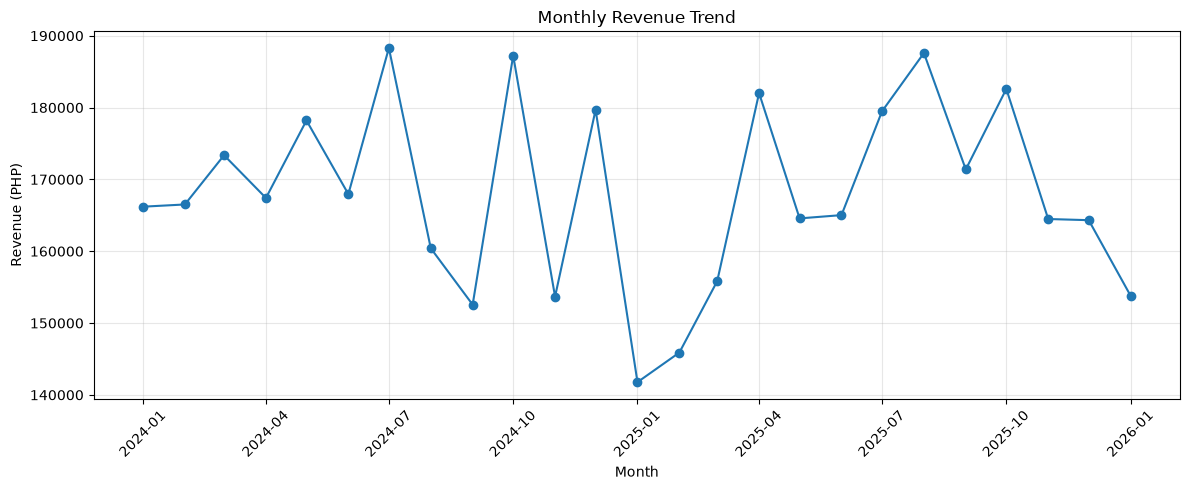

In [19]:
sales['month'] = (
    sales['order_datetime']
    .dt.to_period('M')
)

monthly_revenue = (
    sales.groupby('month')['revenue']
    .sum()
    .reset_index()
)

monthly_revenue['month'] = (
    monthly_revenue['month'].dt.to_timestamp()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue['month'],
    monthly_revenue['revenue'],
    marker='o'
)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (PHP)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

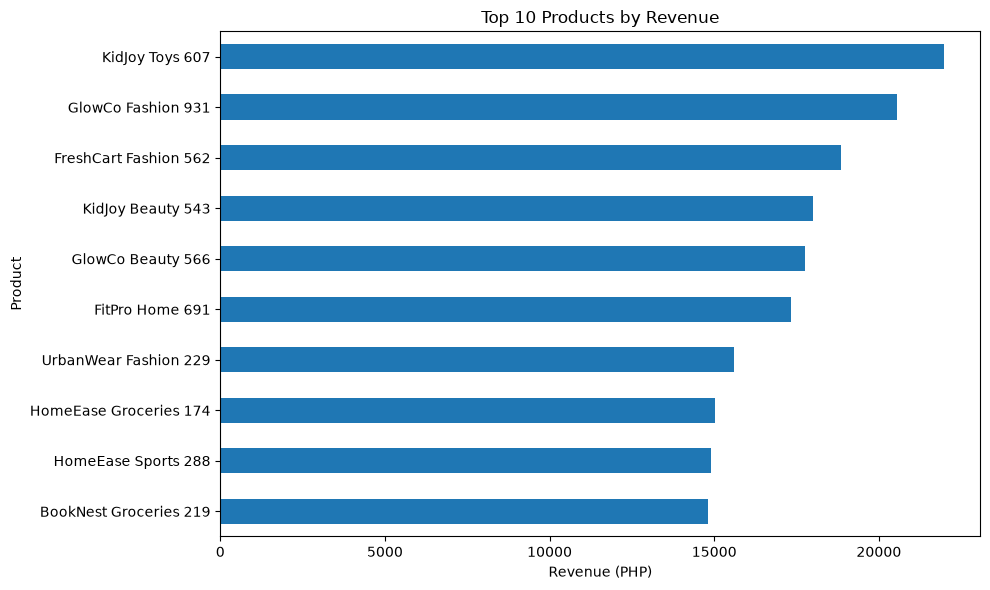

In [21]:
top_products = (
    sales.groupby(
        ['product_id', 'product_name'],
        dropna=False
    )['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products.sort_values('revenue').plot(
    x='product_name',
    y='revenue',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (PHP)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

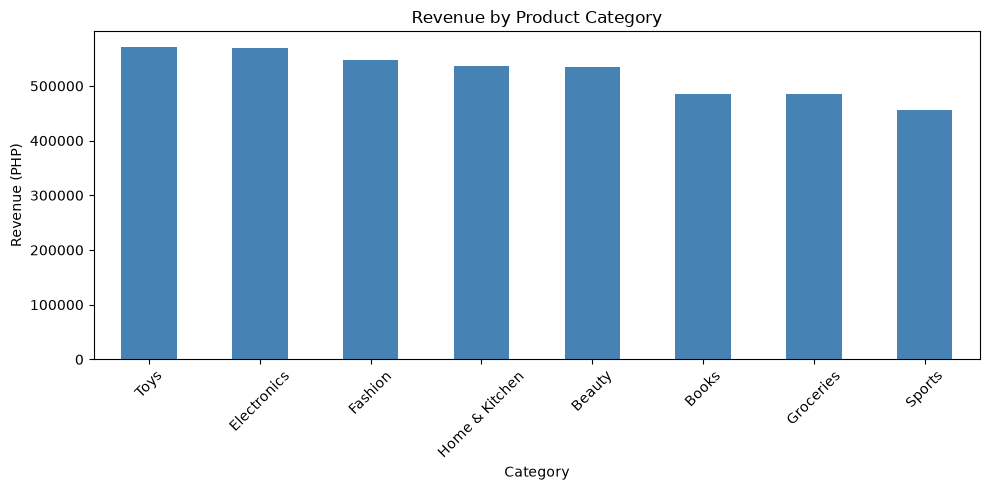

In [31]:
category_revenue = (
    sales.dropna(subset=['category'])
    .loc[lambda df: df['category'].str.strip().str.lower() != 'unknown']
    .groupby('category')['revenue']
    .sum()
    .sort_values(ascending=False)
)

category_revenue.plot(
    kind='bar',
    figsize=(10, 5),
    color='#4682B4'
)

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Revenue (PHP)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

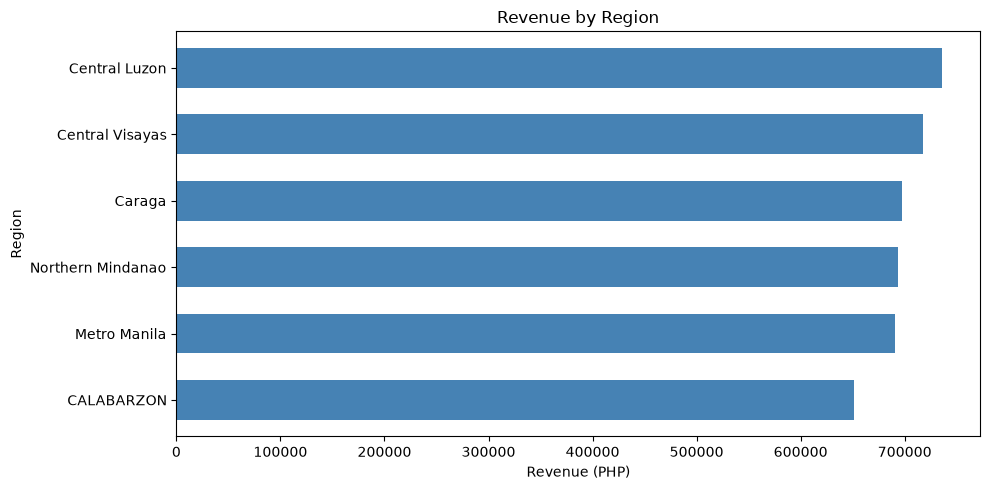

In [36]:
region_revenue = (
    sales.dropna(subset=['region_name'])
    .loc[lambda df: df['region_name'].str.strip().str.lower() != 'unknown']
    .groupby('region_name')['revenue']
    .sum()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 5))

region_revenue.plot(
    kind='barh',
    ax=ax,
    color='#4682B4',
    width=0.6
)

ax.set_title('Revenue by Region')
ax.set_xlabel('Revenue (PHP)')
ax.set_ylabel('Region')

plt.tight_layout()
plt.show()

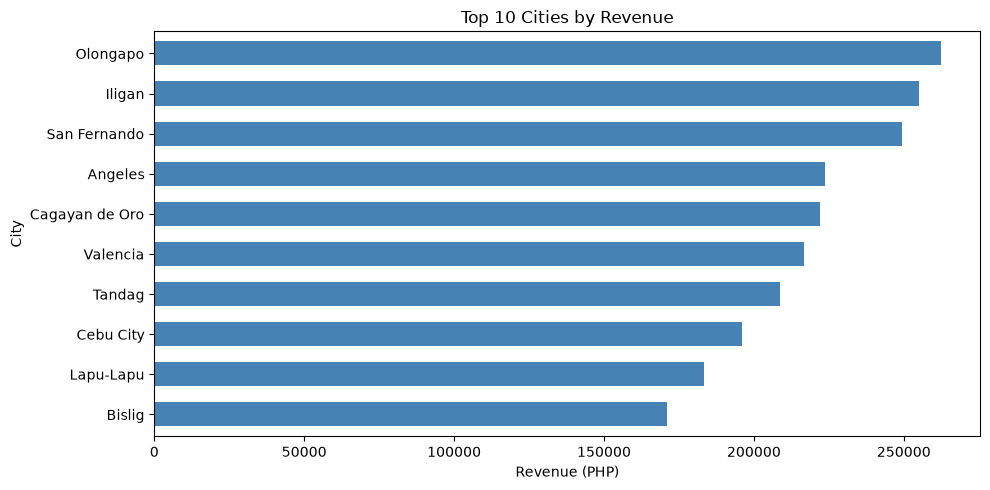

In [38]:
city_revenue = (
    sales.dropna(subset=['city'])
    .loc[lambda df: df['city'].str.strip().str.lower() != 'unknown']
    .groupby('city')['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 5))

city_revenue.plot(
    kind='barh',
    ax=ax,
    color='#4682B4',
    width=0.6
)

ax.set_title('Top 10 Cities by Revenue')
ax.set_xlabel('Revenue (PHP)')
ax.set_ylabel('City')

plt.tight_layout()
plt.show()

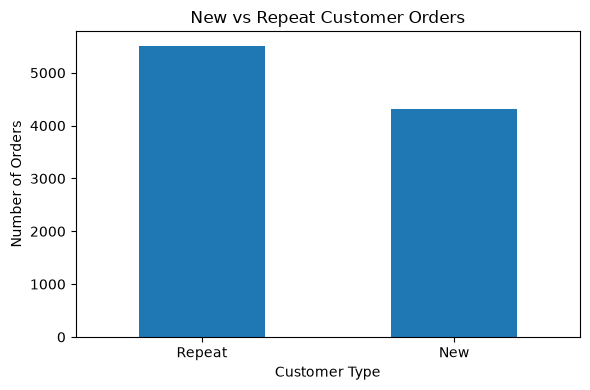

In [39]:
customer_orders = (
    sales[
        ['order_id', 'customer_id', 'order_datetime']
    ]
    .drop_duplicates('order_id')
    .copy()
)

valid_customers = customer_orders[
    customer_orders['customer_id'].isin(
        customers['customer_id']
    )
].copy()

valid_customers = valid_customers.sort_values(
    ['customer_id', 'order_datetime', 'order_id']
)

valid_customers['purchase_number'] = (
    valid_customers.groupby('customer_id')
    .cumcount() + 1
)

valid_customers['customer_type'] = (
    valid_customers['purchase_number']
    .apply(lambda x: 'New' if x == 1 else 'Repeat')
)

valid_customers['customer_type'].value_counts().plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('New vs Repeat Customer Orders')
plt.xlabel('Customer Type')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()